<div align="center">

<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h3><strong>Program Implementasi 5 Studi Kasus Geofisika</strong></h3>
<h3><strong>dengan Data Sintetis &amp; Visualisasi</strong></h3>

<br>

<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>NASRULLAH</span><span>(H061241040)</span></li>
</ul>

<br><br>
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>
<p><strong>2026</strong></p>

</div>




## **Daftar Isi**

| No | Studi Kasus | Metode |
|:--:|:-----------|:------|
| 1 | Geolistrik | Resistivitas 2D |
| 2 | DInSAR | Interferometri SAR Diferensial |
| 3 | InSAR Time Series | Analisis Deformasi Temporal |
| 4 | Seismik Refraksi | Travel Time dan Model Kecepatan |
| 5 | Gravitasi | Bouguer Anomaly |



In [2]:
# ============================================================
#  IMPORT LIBRARY UTAMA
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from scipy import stats
from scipy.ndimage import gaussian_filter
import warnings
warnings.filterwarnings('ignore')

# Pengaturan tampilan global
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

np.random.seed(42)  # Reproducibility

print('Library berhasil diimpor!')
print(f'   NumPy  : {np.__version__}')
print(f'   Pandas : {pd.__version__}')
print('\nSiap menjalankan 5 Studi Kasus Geofisika!')

Library berhasil diimpor!
   NumPy  : 2.5.1
   Pandas : 3.0.5

Siap menjalankan 5 Studi Kasus Geofisika!


# **STUDI KASUS 1: GEOLISTRIK**
## **Interpretasi Penampang Resistivitas 2D**



### Deskripsi Prompt

| Komponen | Keterangan |
|:---------|:-----------|
| **Role** | AI sebagai pendamping interpretasi hasil geolistrik |
| **Task** | Interpretasi penampang resistivitas 2D untuk kondisi bawah permukaan |
| **Context** | Perbedaan resistivitas menggambarkan perbedaan material/kondisi geologi |
| **Input** | Penampang resistivitas 2D, nilai resistivitas, kedalaman, info geologi |
| **Constraints** | Tidak boleh mengolah ulang data atau membuat nilai baru |
| **Output** | Pola resistivitas, pembagian lapisan, kemungkinan material, zona anomali |
| **Quality** | Interpretasi sesuai penampang, bahasa mudah dipahami |
| **Verification** | Cocokkan interpretasi dengan penampang dan info geologi |


In [3]:
# ============================================================
#  STUDI KASUS 1: GEOLISTRIK
#  Pembuatan Data Sintetis Resistivitas 2D
# ============================================================

print('=' * 60)
print('  STUDI KASUS 1: GEOLISTRIK - RESISTIVITAS 2D')
print('=' * 60)

# --- Parameter grid ---
n_elektrode  = 32
spasi        = 5           # meter
panjang_line = (n_elektrode - 1) * spasi
kedalaman_max = 30         # meter

x = np.linspace(0, panjang_line, 80)
z = np.linspace(0, kedalaman_max, 40)
X, Z = np.meshgrid(x, z)

# --- Model resistivitas sintetis ---
# Lapisan 1 (0-5 m)   : Tanah penutup      10-80 ohm.m
# Lapisan 2 (5-18 m)  : Batuan sedimen      80-300 ohm.m
# Lapisan 3 (>18 m)   : Batuan keras        300-800 ohm.m
# Anomali akuifer     : x=60-100 m, z=5-15 m,  2-15 ohm.m
rho = np.zeros_like(X)
for i in range(Z.shape[0]):
    for j in range(Z.shape[1]):
        depth = Z[i, j]
        xpos  = X[i, j]
        if depth < 5:
            base = np.random.uniform(10, 80)
        elif depth < 18:
            base = np.random.uniform(80, 300)
        else:
            base = np.random.uniform(300, 800)
        if 60 <= xpos <= 100 and 5 <= depth <= 15:
            base = np.random.uniform(2, 15)
        if 110 <= xpos <= 130 and depth > 15:
            base = np.random.uniform(1000, 3000)
        rho[i, j] = base

rho_smooth = gaussian_filter(np.log10(rho), sigma=1.5)

print('\nSTATISTIK RESISTIVITAS SINTETIS:')
print('-' * 40)
df_stats = pd.DataFrame({
    'Parameter': ['Minimum (ohm.m)', 'Maksimum (ohm.m)', 'Rata-rata (ohm.m)',
                  'Median (ohm.m)', 'Std Dev (ohm.m)'],
    'Nilai': [f'{rho.min():.2f}', f'{rho.max():.2f}', f'{rho.mean():.2f}',
              f'{np.median(rho):.2f}', f'{rho.std():.2f}']
})
print(df_stats.to_string(index=False))

print('\nTABEL KLASIFIKASI RESISTIVITAS:')
print('-' * 55)
klasifikasi = pd.DataFrame({
    'Rentang (ohm.m)': ['< 10', '10 - 80', '80 - 300', '300 - 800', '> 800'],
    'Material': ['Air tanah/Lempung jenuh', 'Tanah penutup/Alluvium',
                 'Batuan sedimen/Pasir', 'Batuan sedimen kompak', 'Batuan beku/keras'],
    'Lapisan': ['Anomali basah', 'Lapisan 1', 'Lapisan 2', 'Transisi', 'Lapisan 3']
})
print(klasifikasi.to_string(index=False))

  STUDI KASUS 1: GEOLISTRIK - RESISTIVITAS 2D

STATISTIK RESISTIVITAS SINTETIS:
----------------------------------------
        Parameter   Nilai
  Minimum (ohm.m)    2.06
 Maksimum (ohm.m) 2987.70
Rata-rata (ohm.m)  390.84
   Median (ohm.m)  241.98
  Std Dev (ohm.m)  501.03

TABEL KLASIFIKASI RESISTIVITAS:
-------------------------------------------------------
Rentang (ohm.m)                Material       Lapisan
           < 10 Air tanah/Lempung jenuh Anomali basah
        10 - 80  Tanah penutup/Alluvium     Lapisan 1
       80 - 300    Batuan sedimen/Pasir     Lapisan 2
      300 - 800   Batuan sedimen kompak      Transisi
          > 800       Batuan beku/keras     Lapisan 3


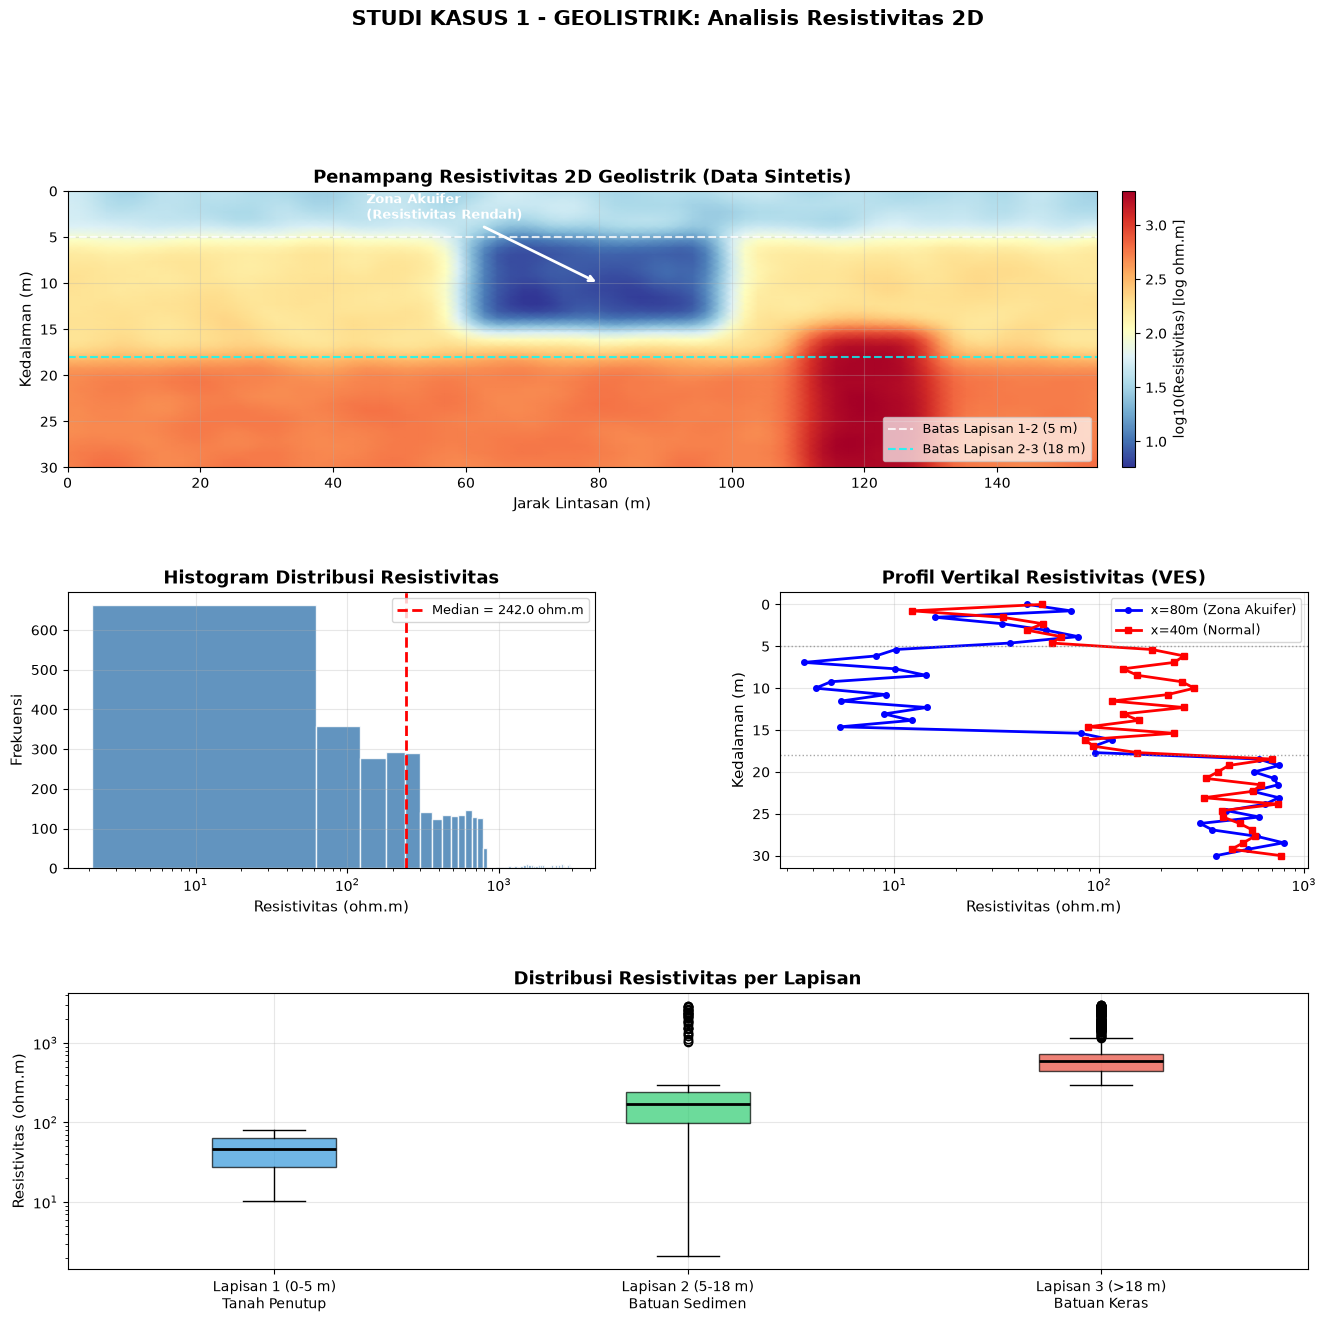

Plot Geolistrik berhasil dibuat dan disimpan!


In [4]:
# ============================================================
#  STUDI KASUS 1: GEOLISTRIK - VISUALISASI (4 PANEL)
# ============================================================

fig = plt.figure(figsize=(16, 14))
gs  = GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# -- Panel 1: Penampang Resistivitas 2D
ax1 = fig.add_subplot(gs[0, :])
im1 = ax1.pcolormesh(X, Z, rho_smooth, cmap='RdYlBu_r', shading='gouraud')
ax1.invert_yaxis()
cb1 = plt.colorbar(im1, ax=ax1, pad=0.02)
cb1.set_label('log10(Resistivitas) [log ohm.m]', fontsize=10)
ax1.set_xlabel('Jarak Lintasan (m)')
ax1.set_ylabel('Kedalaman (m)')
ax1.set_title('Penampang Resistivitas 2D Geolistrik (Data Sintetis)', fontweight='bold')
ax1.annotate('Zona Akuifer\n(Resistivitas Rendah)', xy=(80, 10), xytext=(45, 3),
             arrowprops=dict(arrowstyle='->', color='white', lw=2),
             fontsize=9, color='white', fontweight='bold')
ax1.axhline(y=5,  color='white', ls='--', lw=1.5, alpha=0.8, label='Batas Lapisan 1-2 (5 m)')
ax1.axhline(y=18, color='cyan',  ls='--', lw=1.5, alpha=0.8, label='Batas Lapisan 2-3 (18 m)')
ax1.legend(loc='lower right', fontsize=9, framealpha=0.7)

# -- Panel 2: Histogram
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(rho.flatten(), bins=50, color='steelblue', edgecolor='white', alpha=0.85)
ax2.set_xlabel('Resistivitas (ohm.m)')
ax2.set_ylabel('Frekuensi')
ax2.set_title('Histogram Distribusi Resistivitas', fontweight='bold')
ax2.set_xscale('log')
ax2.axvline(np.median(rho), color='red', lw=2, ls='--',
            label=f'Median = {np.median(rho):.1f} ohm.m')
ax2.legend(fontsize=9)

# -- Panel 3: Profil Vertikal (VES)
ax3 = fig.add_subplot(gs[1, 1])
idx_aqu = np.argmin(np.abs(x - 80))
idx_nor = np.argmin(np.abs(x - 40))
ax3.semilogx(rho[:, idx_aqu], z, 'b-o', markersize=4, label='x=80m (Zona Akuifer)', lw=2)
ax3.semilogx(rho[:, idx_nor], z, 'r-s', markersize=4, label='x=40m (Normal)', lw=2)
ax3.invert_yaxis()
ax3.set_xlabel('Resistivitas (ohm.m)')
ax3.set_ylabel('Kedalaman (m)')
ax3.set_title('Profil Vertikal Resistivitas (VES)', fontweight='bold')
ax3.axhline(y=5,  color='gray', ls=':', lw=1, alpha=0.7)
ax3.axhline(y=18, color='gray', ls=':', lw=1, alpha=0.7)
ax3.legend(fontsize=9)

# -- Panel 4: Boxplot per Lapisan
ax4 = fig.add_subplot(gs[2, :])
lapisan_labels = ['Lapisan 1 (0-5 m)\nTanah Penutup',
                  'Lapisan 2 (5-18 m)\nBatuan Sedimen',
                  'Lapisan 3 (>18 m)\nBatuan Keras']
data_box = [rho[Z < 5].flatten(), rho[(Z >= 5) & (Z < 18)].flatten(), rho[Z >= 18].flatten()]
colors_box = ['#3498db', '#2ecc71', '#e74c3c']
bp = ax4.boxplot(data_box, tick_labels=lapisan_labels, patch_artist=True,
                 medianprops=dict(color='black', lw=2))
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax4.set_yscale('log')
ax4.set_ylabel('Resistivitas (ohm.m)')
ax4.set_title('Distribusi Resistivitas per Lapisan', fontweight='bold')

fig.suptitle('STUDI KASUS 1 - GEOLISTRIK: Analisis Resistivitas 2D',
             fontsize=15, fontweight='bold', y=1.01)
plt.savefig('geolistrik_analisis.png', bbox_inches='tight', dpi=150)
plt.show()
print('Plot Geolistrik berhasil dibuat dan disimpan!')

In [5]:
# ============================================================
#  STUDI KASUS 1: ANALISIS STATISTIK PER LAPISAN
# ============================================================

print('=' * 60)
print('  ANALISIS STATISTIK GEOLISTRIK PER LAPISAN')
print('=' * 60)

lapisan_info = {
    'Lapisan 1 (0-5 m)':   rho[Z < 5],
    'Lapisan 2 (5-18 m)':  rho[(Z >= 5) & (Z < 18)],
    'Lapisan 3 (>18 m)':   rho[Z >= 18]
}

rows = []
for nama, data in lapisan_info.items():
    rows.append({
        'Lapisan': nama,
        'Min (ohm.m)':  f'{data.min():.1f}',
        'Max (ohm.m)':  f'{data.max():.1f}',
        'Mean (ohm.m)': f'{data.mean():.1f}',
        'Median':       f'{np.median(data):.1f}',
        'Std Dev':      f'{data.std():.1f}'
    })

df_lap = pd.DataFrame(rows)
print(df_lap.to_string(index=False))

mask_anom = (X >= 60) & (X <= 100) & (Z >= 5) & (Z <= 15)
rho_anom  = rho[mask_anom]
print('\nZONA ANOMALI (Akuifer: x=60-100 m, z=5-15 m):')
print(f'  Rata-rata  : {rho_anom.mean():.2f} ohm.m')
print(f'  Minimum    : {rho_anom.min():.2f} ohm.m')
print(f'  Maksimum   : {rho_anom.max():.2f} ohm.m')

print('\nINTERPRETASI OTOMATIS:')
print('-' * 55)
print('''
  Lapisan 1 (0-5 m): Resistivitas 10-80 ohm.m
    -> Kemungkinan lapisan tanah penutup (top soil) atau
       aluvium yang bersifat lembap.

  Lapisan 2 (5-18 m): Resistivitas 80-300 ohm.m
    -> Menunjukkan lapisan batuan sedimen atau pasir padat.
       Variasi resistivitas mengindikasikan heterogenitas material.

  Lapisan 3 (>18 m): Resistivitas 300-800+ ohm.m
    -> Kemungkinan batuan dasar (bedrock) atau batuan beku
       yang memiliki resistivitas tinggi.

  ZONA ANOMALI (x=60-100 m, z=5-15 m): Resistivitas < 15 ohm.m
    -> Nilai resistivitas sangat rendah mengindikasikan adanya
       zona jenuh air / potensi akuifer.
       Perlu konfirmasi dengan data sumur bor atau hidrogeologi.
''')

  ANALISIS STATISTIK GEOLISTRIK PER LAPISAN
           Lapisan Min (ohm.m) Max (ohm.m) Mean (ohm.m) Median Std Dev
 Lapisan 1 (0-5 m)        10.4        80.0         45.5   46.6    20.9
Lapisan 2 (5-18 m)         2.1      2953.6        210.9  169.7   348.1
 Lapisan 3 (>18 m)       300.0      2987.7        733.1  589.9   543.0

ZONA ANOMALI (Akuifer: x=60-100 m, z=5-15 m):
  Rata-rata  : 8.04 ohm.m
  Minimum    : 2.06 ohm.m
  Maksimum   : 14.93 ohm.m

INTERPRETASI OTOMATIS:
-------------------------------------------------------

  Lapisan 1 (0-5 m): Resistivitas 10-80 ohm.m
    -> Kemungkinan lapisan tanah penutup (top soil) atau
       aluvium yang bersifat lembap.

  Lapisan 2 (5-18 m): Resistivitas 80-300 ohm.m
    -> Menunjukkan lapisan batuan sedimen atau pasir padat.
       Variasi resistivitas mengindikasikan heterogenitas material.

  Lapisan 3 (>18 m): Resistivitas 300-800+ ohm.m
    -> Kemungkinan batuan dasar (bedrock) atau batuan beku
       yang memiliki resistivitas tingg



# **STUDI KASUS 2: DInSAR**
## **Analisis Deformasi Permukaan - Differential Interferometric SAR**



### Deskripsi Prompt (RTCIKQOV)

| Komponen | Keterangan |
|:---------|:-----------|
| **Role** | AI sebagai pendamping interpretasi hasil DInSAR |
| **Task** | Melihat dan menginterpretasikan pola deformasi permukaan |
| **Context** | DInSAR melihat perubahan permukaan dari dua waktu pengamatan |
| **Input** | Interferogram, peta displacement, nilai displacement, info gempa/geologi |
| **Constraints** | Tidak mengolah ulang data; tidak semua perubahan warna = deformasi |
| **Output** | Wilayah deformasi, besar dan arah perubahan, kemungkinan penyebab |
| **Quality** | Interpretasi berbasis hasil, bedakan pengamatan dan dugaan |
| **Verification** | Bandingkan dengan data gempa, GNSS, atau geologi |


In [6]:
# ============================================================
#  STUDI KASUS 2: DInSAR
#  Pembuatan Data Sintetis Interferogram & Displacement
# ============================================================

print('=' * 60)
print('  STUDI KASUS 2: DInSAR - DEFORMASI PERMUKAAN')
print('=' * 60)

nx, ny = 120, 100
x_km   = np.linspace(0, 60, nx)
y_km   = np.linspace(0, 50, ny)
Xk, Yk = np.meshgrid(x_km, y_km)

epi_x, epi_y = 30.0, 25.0
Mw           = 6.2

dist = np.sqrt((Xk - epi_x)**2 + (Yk - epi_y)**2)

# Model deformasi: zona uplift dan subsidence
disp_up   = 8.0  * np.exp(-dist**2 / (2 * 12**2))
disp_down = -4.0 * np.exp(-((Xk-42)**2 + (Yk-30)**2) / (2 * 8**2))
displacement = disp_up + disp_down
displacement += gaussian_filter(np.random.randn(ny, nx) * 0.8, sigma=3)

# Interferogram (wrapped phase)
wavelength   = 5.6   # cm (Sentinel-1 C-band)
phase        = (4 * np.pi / wavelength) * displacement
interferogram = np.mod(phase, 2 * np.pi)
n_fringe = (displacement.max() - displacement.min()) / (wavelength / 2)

print('\nSTATISTIK DISPLACEMENT (LOS):')
print('-' * 45)
df_disp = pd.DataFrame({
    'Parameter': ['Min (cm)', 'Max (cm)', 'Rata-rata (cm)',
                  'Median (cm)', 'Std Dev (cm)',
                  'Piksel uplift (>0)', 'Piksel subsidence (<0)'],
    'Nilai': [f'{displacement.min():.2f}', f'{displacement.max():.2f}',
              f'{displacement.mean():.2f}', f'{np.median(displacement):.2f}',
              f'{displacement.std():.2f}',
              f'{(displacement > 0).sum()}', f'{(displacement < 0).sum()}']
})
print(df_disp.to_string(index=False))
print(f'\nSkenario: Gempa sintetis Mw {Mw} di ({epi_x}, {epi_y}) km')
print(f'Estimasi jumlah fringe: {n_fringe:.1f} fringe')

  STUDI KASUS 2: DInSAR - DEFORMASI PERMUKAAN

STATISTIK DISPLACEMENT (LOS):
---------------------------------------------
             Parameter Nilai
              Min (cm) -0.85
              Max (cm)  7.23
        Rata-rata (cm)  1.74
           Median (cm)  1.03
          Std Dev (cm)  1.90
    Piksel uplift (>0) 11039
Piksel subsidence (<0)   961

Skenario: Gempa sintetis Mw 6.2 di (30.0, 25.0) km
Estimasi jumlah fringe: 2.9 fringe


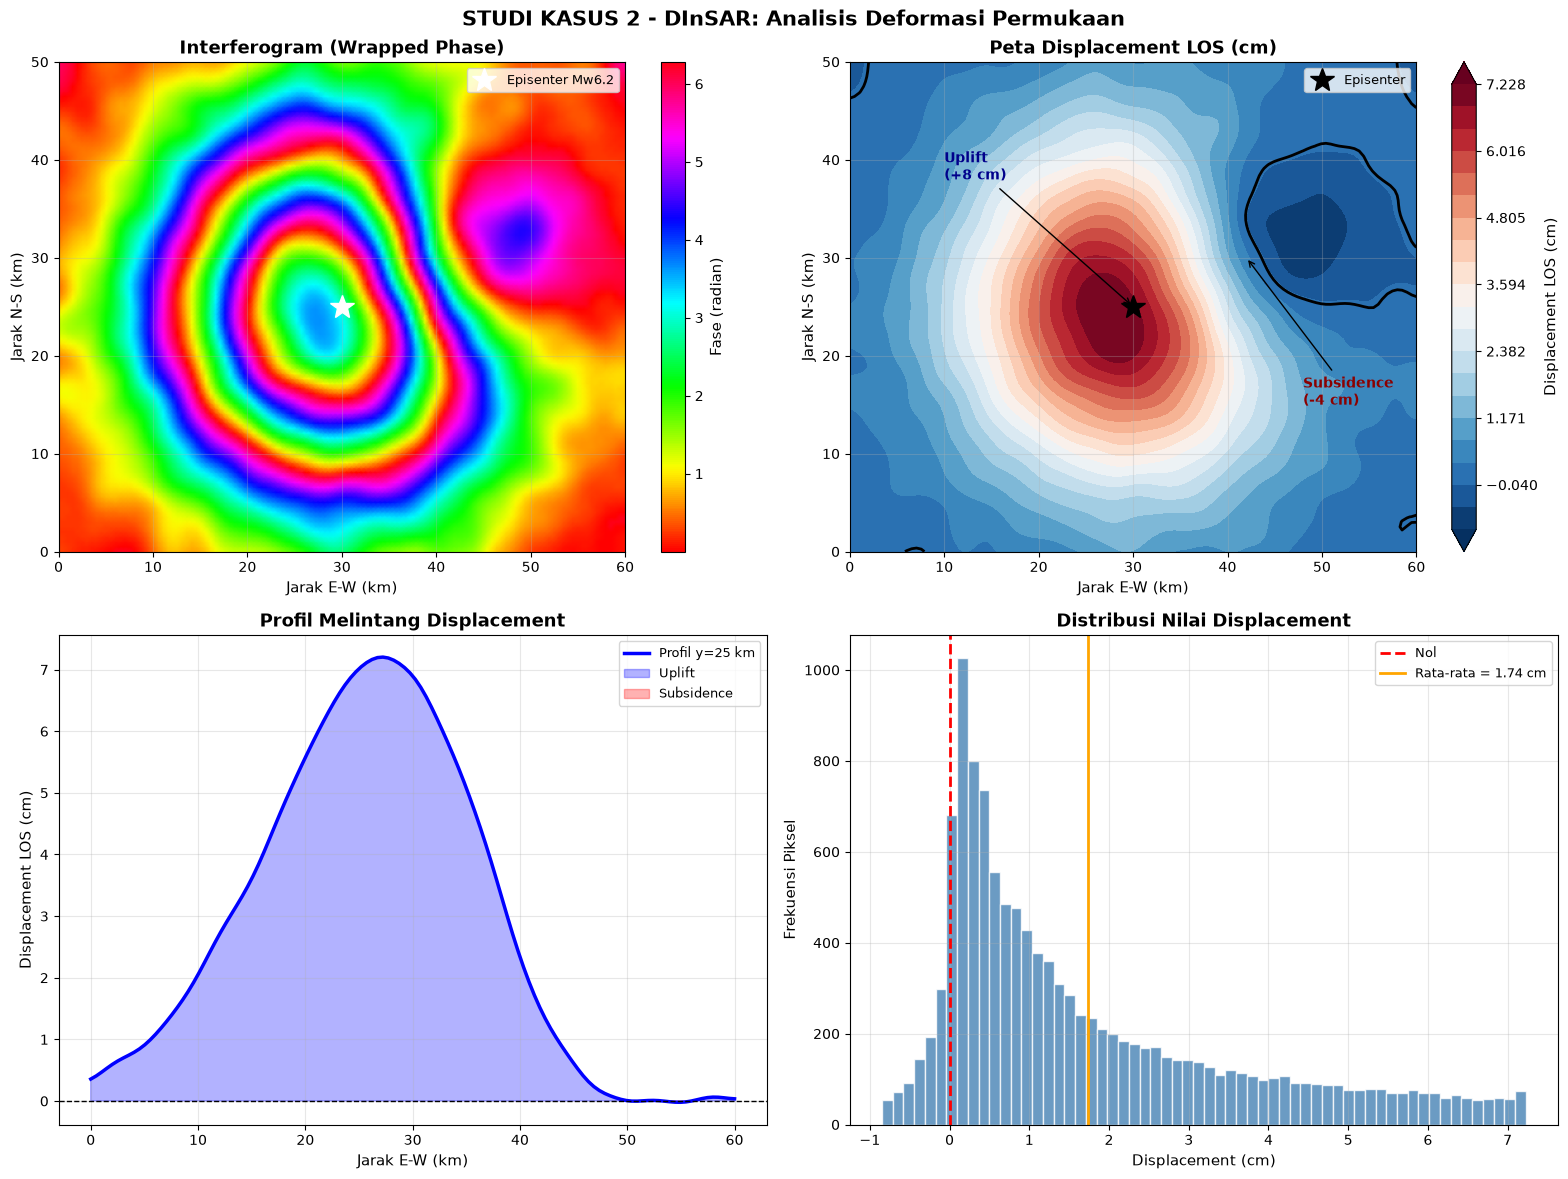

Plot DInSAR berhasil dibuat!


In [7]:
# ============================================================
#  STUDI KASUS 2: DInSAR - VISUALISASI (4 PANEL)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('STUDI KASUS 2 - DInSAR: Analisis Deformasi Permukaan',
             fontsize=15, fontweight='bold')

# -- Panel 1: Interferogram
ax = axes[0, 0]
im = ax.pcolormesh(Xk, Yk, interferogram, cmap='hsv', shading='gouraud')
plt.colorbar(im, ax=ax, label='Fase (radian)')
ax.plot(epi_x, epi_y, 'w*', markersize=18, label=f'Episenter Mw{Mw}', zorder=5)
ax.set_xlabel('Jarak E-W (km)')
ax.set_ylabel('Jarak N-S (km)')
ax.set_title('Interferogram (Wrapped Phase)', fontweight='bold')
ax.legend(fontsize=9)

# -- Panel 2: Peta Displacement
ax = axes[0, 1]
levels = np.linspace(displacement.min(), displacement.max(), 21)
im2 = ax.contourf(Xk, Yk, displacement, levels=levels, cmap='RdBu_r', extend='both')
plt.colorbar(im2, ax=ax, label='Displacement LOS (cm)')
ax.contour(Xk, Yk, displacement, levels=[0], colors='k', linewidths=2)
ax.plot(epi_x, epi_y, 'k*', markersize=18, label='Episenter', zorder=5)
ax.set_xlabel('Jarak E-W (km)')
ax.set_ylabel('Jarak N-S (km)')
ax.set_title('Peta Displacement LOS (cm)', fontweight='bold')
ax.legend(fontsize=9)
ax.annotate('Uplift\n(+8 cm)', xy=(30, 25), xytext=(10, 38),
            arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=10, fontweight='bold', color='darkblue')
ax.annotate('Subsidence\n(-4 cm)', xy=(42, 30), xytext=(48, 15),
            arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=10, fontweight='bold', color='darkred')

# -- Panel 3: Profil Melintang
ax = axes[1, 0]
row_mid = ny // 2
ax.plot(x_km, displacement[row_mid, :], 'b-', lw=2.5, label='Profil y=25 km')
ax.axhline(0, color='black', lw=1, ls='--')
ax.fill_between(x_km, displacement[row_mid, :], 0,
                where=displacement[row_mid, :] > 0, alpha=0.3, color='blue', label='Uplift')
ax.fill_between(x_km, displacement[row_mid, :], 0,
                where=displacement[row_mid, :] < 0, alpha=0.3, color='red', label='Subsidence')
ax.set_xlabel('Jarak E-W (km)')
ax.set_ylabel('Displacement LOS (cm)')
ax.set_title('Profil Melintang Displacement', fontweight='bold')
ax.legend(fontsize=9)

# -- Panel 4: Histogram
ax = axes[1, 1]
ax.hist(displacement.flatten(), bins=60, color='steelblue', edgecolor='white', alpha=0.8)
ax.axvline(0, color='red', lw=2, ls='--', label='Nol')
ax.axvline(displacement.mean(), color='orange', lw=2,
           label=f'Rata-rata = {displacement.mean():.2f} cm')
ax.set_xlabel('Displacement (cm)')
ax.set_ylabel('Frekuensi Piksel')
ax.set_title('Distribusi Nilai Displacement', fontweight='bold')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('dinsar_analisis.png', bbox_inches='tight', dpi=150)
plt.show()
print('Plot DInSAR berhasil dibuat!')

In [8]:
# ============================================================
#  STUDI KASUS 2: DInSAR - ANALISIS STATISTIK
# ============================================================

print('=' * 60)
print('  ANALISIS STATISTIK DInSAR')
print('=' * 60)

zona_uplift     = displacement[displacement > 1.0]
zona_subsidence = displacement[displacement < -1.0]
zona_stabil     = displacement[np.abs(displacement) <= 1.0]

df_zona = pd.DataFrame({
    'Zona': ['Uplift (>1 cm)', 'Subsidence (<-1 cm)', 'Stabil (+-1 cm)'],
    'Jumlah Piksel': [len(zona_uplift), len(zona_subsidence), len(zona_stabil)],
    'Max Deformasi': [
        f'+{zona_uplift.max():.2f} cm' if len(zona_uplift) > 0 else 'N/A',
        f'{zona_subsidence.min():.2f} cm' if len(zona_subsidence) > 0 else 'N/A',
        'N/A'
    ],
    'Mean (cm)': [
        f'{zona_uplift.mean():.2f}' if len(zona_uplift) > 0 else 'N/A',
        f'{zona_subsidence.mean():.2f}' if len(zona_subsidence) > 0 else 'N/A',
        f'{zona_stabil.mean():.2f}' if len(zona_stabil) > 0 else 'N/A'
    ]
})
print(df_zona.to_string(index=False))
print(f'\nEstimasi jumlah fringe: {n_fringe:.1f} fringe')
print(f'(1 fringe = {wavelength/2:.1f} cm deformasi LOS)')

print('\nINTERPRETASI OTOMATIS:')
print('-' * 55)
print(f'''
  Berdasarkan hasil DInSAR sintetis skenario gempa Mw {Mw}:

  INTERFEROGRAM:
    Pola fringe konsentris di sekitar episenter ({epi_x}, {epi_y}) km.
    Setiap fringe mewakili deformasi +/-{wavelength/2:.1f} cm (LOS).

  ZONA UPLIFT:
    Deformasi positif hingga +{displacement.max():.1f} cm di sekitar
    episenter, mengindikasikan pengangkatan permukaan akibat
    mekanisme sesar naik (thrust fault).

  ZONA SUBSIDENCE:
    Deformasi negatif hingga {displacement.min():.1f} cm di sisi tenggara,
    menunjukkan penurunan permukaan sebagai respons co-seismic.

  CATATAN:
    Interpretasi perlu diverifikasi dengan data GPS/GNSS
    dan katalog gempa (BMKG/USGS) untuk validasi.
''')


  ANALISIS STATISTIK DInSAR
               Zona  Jumlah Piksel Max Deformasi Mean (cm)
     Uplift (>1 cm)           6076      +7.23 cm      3.13
Subsidence (<-1 cm)              0           N/A       N/A
    Stabil (+-1 cm)           5924           N/A      0.31

Estimasi jumlah fringe: 2.9 fringe
(1 fringe = 2.8 cm deformasi LOS)

INTERPRETASI OTOMATIS:
-------------------------------------------------------

  Berdasarkan hasil DInSAR sintetis skenario gempa Mw 6.2:

  INTERFEROGRAM:
    Pola fringe konsentris di sekitar episenter (30.0, 25.0) km.
    Setiap fringe mewakili deformasi +/-2.8 cm (LOS).

  ZONA UPLIFT:
    Deformasi positif hingga +7.2 cm di sekitar
    episenter, mengindikasikan pengangkatan permukaan akibat
    mekanisme sesar naik (thrust fault).

  ZONA SUBSIDENCE:
    Deformasi negatif hingga -0.8 cm di sisi tenggara,
    menunjukkan penurunan permukaan sebagai respons co-seismic.

  CATATAN:
    Interpretasi perlu diverifikasi dengan data GPS/GNSS
    dan katalog



# **STUDI KASUS 3: InSAR TIME SERIES**
## **Analisis Deformasi Temporal - Velocity Map dan Time Series**

### Deskripsi Prompt (RTCIKQOV)

| Komponen | Keterangan |
|:---------|:-----------|
| **Role** | AI sebagai pendamping interpretasi hasil InSAR |
| **Task** | Menginterpretasikan deformasi berbasis peta kecepatan dan grafik temporal |
| **Context** | InSAR melihat perubahan dari beberapa waktu pengamatan (spasial & temporal) |
| **Input** | Velocity map, grafik time series, nilai displacement, lokasi titik |
| **Constraints** | Tidak mengolah ulang data; gunakan nilai, satuan, legenda yang tersedia |
| **Output** | Wilayah deformasi, arah perubahan, pola terhadap waktu |
| **Quality** | Sesuai peta dan grafik; tidak melebihi informasi yang tersedia |
| **Verification** | Bandingkan grafik dengan velocity map dan data pembanding |


In [9]:
# ============================================================
#  STUDI KASUS 3: InSAR TIME SERIES
#  Pembuatan Data Sintetis Velocity Map dan Time Series
# ============================================================

print('=' * 60)
print('  STUDI KASUS 3: InSAR TIME SERIES')
print('=' * 60)

nx_ts, ny_ts = 100, 80
x_ts  = np.linspace(0, 50, nx_ts)
y_ts  = np.linspace(0, 40, ny_ts)
Xt, Yt = np.meshgrid(x_ts, y_ts)

# Velocity map: skenario land subsidence
vel_subsidence = -30.0 * np.exp(-((Xt - 25)**2 + (Yt - 20)**2) / (2 * 8**2))
vel_uplift     =  +8.0 * np.exp(-((Xt -  8)**2 + (Yt - 15)**2) / (2 * 5**2))
vel_map = vel_subsidence + vel_uplift
vel_map += gaussian_filter(np.random.randn(ny_ts, nx_ts) * 1.5, sigma=2)

# Time series 3 titik (2020-2023, 90 epoch, tiap 12 hari)
n_epochs = 90
dates    = pd.date_range(start='2020-01-01', periods=n_epochs, freq='12D')
t_years  = np.arange(n_epochs) * 12 / 365.25

ts_A = -30 * t_years + 5 * np.sin(2*np.pi*t_years) + np.random.randn(n_epochs)*2
ts_B = -10 * t_years + 3 * np.sin(2*np.pi*t_years + 0.5) + np.random.randn(n_epochs)*2
ts_C =  0.5* t_years + 2 * np.sin(2*np.pi*t_years) + np.random.randn(n_epochs)*2

def linear_rate(t, disp):
    slope, intercept, r, p, se = stats.linregress(t, disp)
    return slope, intercept, r**2

rate_A, int_A, r2_A = linear_rate(t_years, ts_A)
rate_B, int_B, r2_B = linear_rate(t_years, ts_B)
rate_C, int_C, r2_C = linear_rate(t_years, ts_C)

print('\nSTATISTIK VELOCITY MAP:')
print(f'  Min : {vel_map.min():.2f} mm/tahun')
print(f'  Max : {vel_map.max():.2f} mm/tahun')
print(f'  Mean: {vel_map.mean():.2f} mm/tahun')

print('\nLAJU DEFORMASI TITIK PENGAMATAN:')
df_ts = pd.DataFrame({
    'Titik': ['A (Pusat Subsidence)', 'B (Tepi Subsidence)', 'C (Zona Stabil)'],
    'Laju (mm/thn)': [f'{rate_A:.2f}', f'{rate_B:.2f}', f'{rate_C:.2f}'],
    'R2 Regresi':    [f'{r2_A:.3f}',   f'{r2_B:.3f}',   f'{r2_C:.3f}'],
    'Total Disp (mm)': [f'{ts_A[-1]-ts_A[0]:.1f}', f'{ts_B[-1]-ts_B[0]:.1f}',
                        f'{ts_C[-1]-ts_C[0]:.1f}']
})
print(df_ts.to_string(index=False))

  STUDI KASUS 3: InSAR TIME SERIES

STATISTIK VELOCITY MAP:
  Min : -29.75 mm/tahun
  Max : 5.90 mm/tahun
  Mean: -5.23 mm/tahun

LAJU DEFORMASI TITIK PENGAMATAN:
               Titik Laju (mm/thn) R2 Regresi Total Disp (mm)
A (Pusat Subsidence)        -31.08      0.980           -86.7
 B (Tepi Subsidence)        -10.89      0.927           -30.9
     C (Zona Stabil)          0.26      0.007             7.7


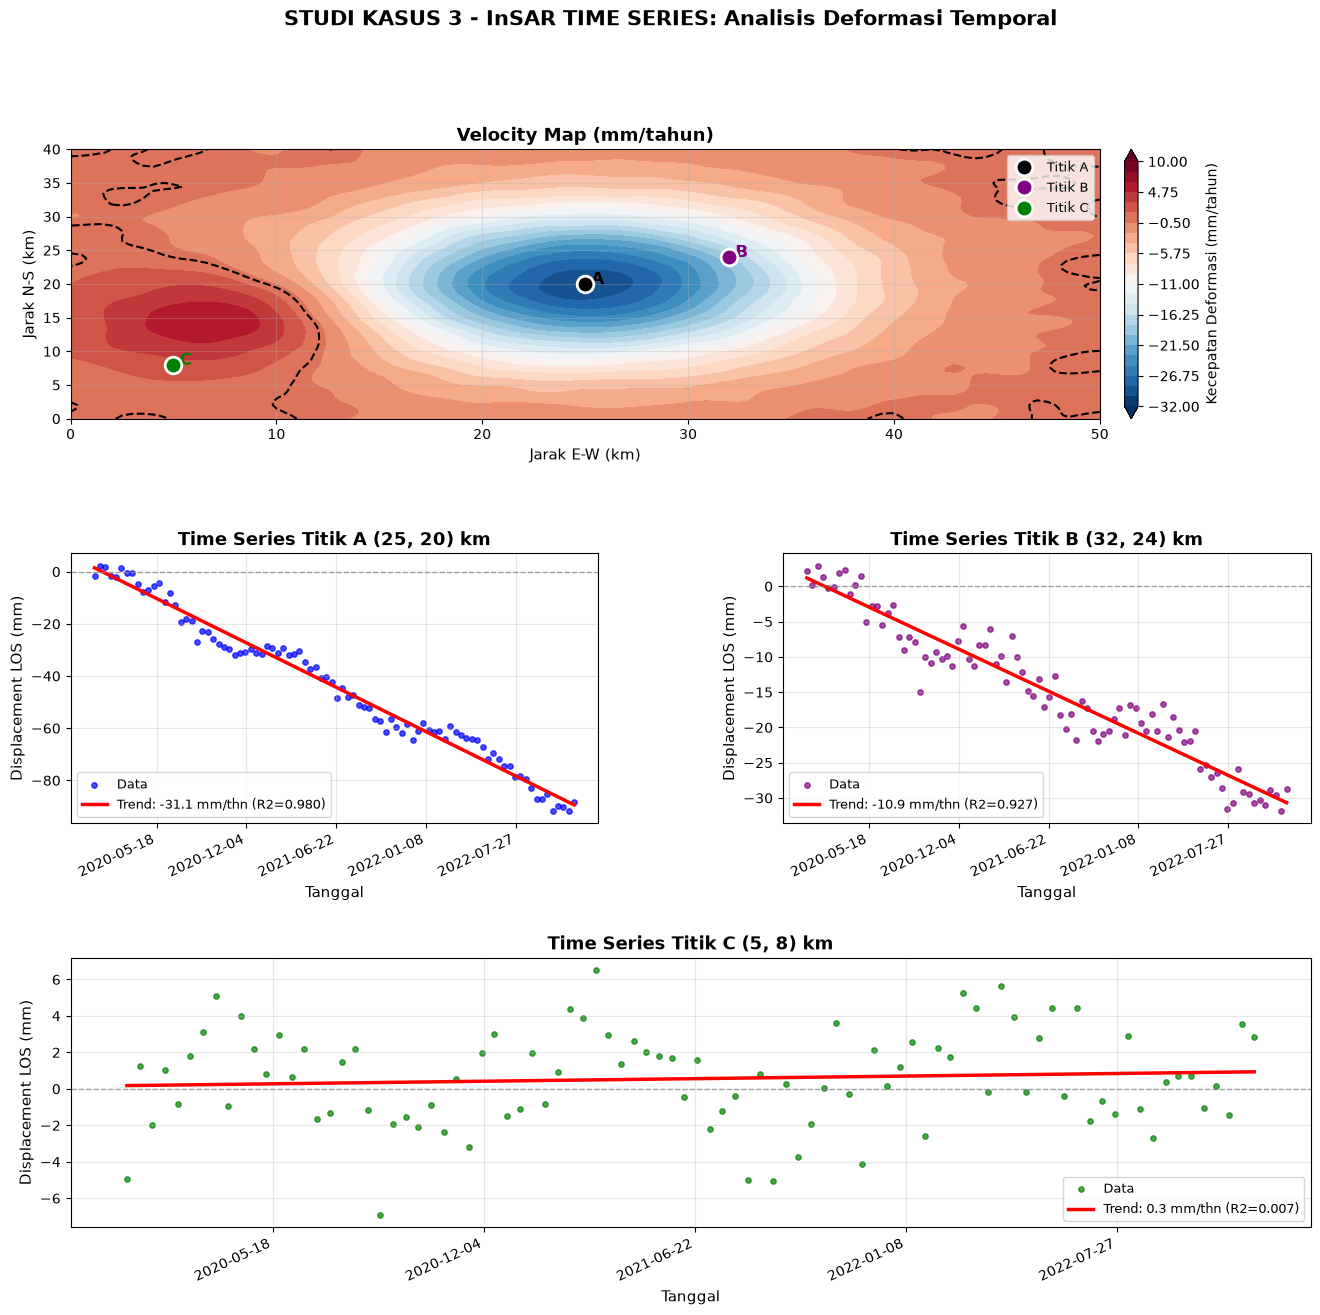

Plot InSAR Time Series berhasil dibuat!


In [10]:
# ============================================================
#  STUDI KASUS 3: InSAR TIME SERIES - VISUALISASI (4 PANEL)
# ============================================================

fig = plt.figure(figsize=(16, 14))
gs  = GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
fig.suptitle('STUDI KASUS 3 - InSAR TIME SERIES: Analisis Deformasi Temporal',
             fontsize=15, fontweight='bold')

# -- Panel 1: Velocity Map
ax1 = fig.add_subplot(gs[0, :])
lev_v = np.linspace(-32, 10, 25)
im1 = ax1.contourf(Xt, Yt, vel_map, levels=lev_v, cmap='RdBu_r', extend='both')
cb1 = plt.colorbar(im1, ax=ax1, pad=0.02)
cb1.set_label('Kecepatan Deformasi (mm/tahun)', fontsize=10)
ax1.contour(Xt, Yt, vel_map, levels=[0], colors='k', linewidths=1.5, linestyles='--')

titik_coords = {'A': (25, 20), 'B': (32, 24), 'C': (5, 8)}
colors_pt    = {'A': 'black', 'B': 'purple', 'C': 'green'}
for nama, (px, py) in titik_coords.items():
    ax1.plot(px, py, 'o', color=colors_pt[nama], markersize=12, zorder=5,
             markeredgecolor='white', markeredgewidth=2, label=f'Titik {nama}')
    ax1.annotate(f' {nama}', xy=(px, py), fontsize=12, fontweight='bold',
                 color=colors_pt[nama])

ax1.set_xlabel('Jarak E-W (km)')
ax1.set_ylabel('Jarak N-S (km)')
ax1.set_title('Velocity Map (mm/tahun)', fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)

# -- Panel 2-4: Time Series A, B, C
ts_data = [
    (ts_A, rate_A, int_A, r2_A, 'A', (25,20), 'blue',   gs[1, 0]),
    (ts_B, rate_B, int_B, r2_B, 'B', (32,24), 'purple', gs[1, 1]),
    (ts_C, rate_C, int_C, r2_C, 'C', (5, 8),  'green',  gs[2, :]),
]

for (ts, rate, intercept, r2, nama, koord, col, pos) in ts_data:
    ax = fig.add_subplot(pos)
    ax.scatter(dates, ts, s=15, alpha=0.7, color=col, label='Data')
    trend = rate * t_years + intercept
    ax.plot(dates, trend, 'r-', lw=2.5, label=f'Trend: {rate:.1f} mm/thn (R2={r2:.3f})')
    ax.axhline(0, color='gray', lw=1, ls='--', alpha=0.7)
    ax.set_xlabel('Tanggal')
    ax.set_ylabel('Displacement LOS (mm)')
    ax.set_title(f'Time Series Titik {nama} ({koord[0]}, {koord[1]}) km', fontweight='bold')
    ax.legend(fontsize=9)
    ax.xaxis.set_major_locator(ticker.MaxNLocator(6))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=25, ha='right')

plt.savefig('insar_timeseries_analisis.png', bbox_inches='tight', dpi=150)
plt.show()
print('Plot InSAR Time Series berhasil dibuat!')

In [11]:
# ============================================================
#  STUDI KASUS 3: InSAR TIME SERIES - ANALISIS
# ============================================================

print('=' * 60)
print('  ANALISIS InSAR TIME SERIES')
print('=' * 60)

for ts, rate, r2, nama, koord in [
    (ts_A, rate_A, r2_A, 'A', (25,20)),
    (ts_B, rate_B, r2_B, 'B', (32,24)),
    (ts_C, rate_C, r2_C, 'C', (5,8))
]:
    print(f'\n  Titik {nama} ({koord[0]}, {koord[1]} km):')
    print(f'    Laju deformasi : {rate:.2f} mm/tahun')
    print(f'    R2 regresi     : {r2:.4f}')
    print(f'    Total disp     : {ts[-1]-ts[0]:.1f} mm')
    if rate < -20:
        status = 'SUBSIDENCE CEPAT - perlu perhatian'
    elif rate < -5:
        status = 'SUBSIDENCE SEDANG'
    elif rate > 3:
        status = 'UPLIFT - pengangkatan permukaan'
    else:
        status = 'RELATIF STABIL'
    print(f'    Status         : {status}')

print('\nINTERPRETASI OTOMATIS:')
print('-' * 55)
print(f'''
  Berdasarkan velocity map dan time series InSAR:

  VELOCITY MAP:
    Zona subsidence utama di sekitar (25, 20) km dengan
    kecepatan penurunan hingga ~-30 mm/tahun.
    Zona pengangkatan kecil (+8 mm/tahun) terlihat di barat.

  TITIK A (Pusat Subsidence): {rate_A:.1f} mm/tahun
    Tren penurunan konsisten sepanjang periode amatan.
    Kemungkinan disebabkan ekstraksi air tanah berlebihan
    atau pemadatan sedimen.

  TITIK B (Tepi Zona): {rate_B:.1f} mm/tahun
    Penurunan sedang, masih dalam jangkauan zona subsidence.

  TITIK C (Zona Stabil): {rate_C:.1f} mm/tahun
    Relatif stabil, dapat dijadikan titik referensi.

  POLA MUSIMAN:
    Terdeteksi fluktuasi musiman pada semua titik, kemungkinan
    terkait perubahan muka air tanah atau beban hidrologis.
''')

  ANALISIS InSAR TIME SERIES

  Titik A (25, 20 km):
    Laju deformasi : -31.08 mm/tahun
    R2 regresi     : 0.9797
    Total disp     : -86.7 mm
    Status         : SUBSIDENCE CEPAT - perlu perhatian

  Titik B (32, 24 km):
    Laju deformasi : -10.89 mm/tahun
    R2 regresi     : 0.9266
    Total disp     : -30.9 mm
    Status         : SUBSIDENCE SEDANG

  Titik C (5, 8 km):
    Laju deformasi : 0.26 mm/tahun
    R2 regresi     : 0.0071
    Total disp     : 7.7 mm
    Status         : RELATIF STABIL

INTERPRETASI OTOMATIS:
-------------------------------------------------------

  Berdasarkan velocity map dan time series InSAR:

  VELOCITY MAP:
    Zona subsidence utama di sekitar (25, 20) km dengan
    kecepatan penurunan hingga ~-30 mm/tahun.
    Zona pengangkatan kecil (+8 mm/tahun) terlihat di barat.

  TITIK A (Pusat Subsidence): -31.1 mm/tahun
    Tren penurunan konsisten sepanjang periode amatan.
    Kemungkinan disebabkan ekstraksi air tanah berlebihan
    atau pemadatan 


# **STUDI KASUS 4: SEISMIK REFRAKSI**
## **Analisis Travel Time dan Model Kecepatan Lapisan**


### Deskripsi Prompt (RTCIKQOV)

| Komponen | Keterangan |
|:---------|:-----------|
| **Role** | AI sebagai pendamping interpretasi hasil seismik refraksi |
| **Task** | Menginterpretasikan hasil seismik refraksi untuk gambaran lapisan bawah permukaan |
| **Context** | Waktu tiba gelombang memberikan informasi kecepatan dan kedalaman lapisan |
| **Input** | Kurva travel time, model kecepatan, kedalaman lapisan, info geologi |
| **Constraints** | Tidak menghitung ulang; hati-hati identifikasi batuan dari kecepatan |
| **Output** | Jumlah lapisan, perbedaan kecepatan, kedalaman batas, kemungkinan material |
| **Quality** | Sesuai model kecepatan; mempertimbangkan informasi geologi |
| **Verification** | Cocokkan interpretasi lapisan dengan model kecepatan dan data geologi |


In [12]:
# ============================================================
#  STUDI KASUS 4: SEISMIK REFRAKSI
#  Pembuatan Data Sintetis Travel Time dan Model Kecepatan
# ============================================================

print('=' * 60)
print('  STUDI KASUS 4: SEISMIK REFRAKSI')
print('=' * 60)

# Model 3 lapisan:
# Lapisan 1: V1=400  m/s, H1=8  m  - Soil / tanah lepas
# Lapisan 2: V2=1200 m/s, H2=20 m  - Batuan sedimen
# Lapisan 3: V3=3500 m/s            - Batuan dasar (bedrock)

V1, V2, V3 = 400.0, 1200.0, 3500.0   # m/s
H1, H2     = 8.0, 20.0               # m

offsets = np.arange(2, 102, 2)   # 2 to 100 m

# Waktu tempuh
t_direct = offsets / V1

i12 = np.arcsin(V1 / V2)
t_ic12  = 2 * H1 * np.cos(i12) / V1
t_refr2 = offsets / V2 + t_ic12

i13 = np.arcsin(V1 / V3)
i23 = np.arcsin(V2 / V3)
t_ic3   = (2 * H1 * np.cos(i13) / V1) + (2 * H2 * np.cos(i23) / V2)
t_refr3 = offsets / V3 + t_ic3

t_obs_clean = np.minimum(t_direct, np.minimum(t_refr2, t_refr3))
t_observed  = t_obs_clean + t_obs_clean * 0.02 * np.random.randn(len(offsets))

xc12 = 2 * H1 * np.sqrt((V2 + V1) / (V2 - V1))
rms_resid = np.sqrt(np.mean(((t_observed - t_obs_clean) * 1000)**2))

print('\nMODEL KECEPATAN 3 LAPISAN:')
print('-' * 55)
df_model = pd.DataFrame({
    'Lapisan': ['Lapisan 1', 'Lapisan 2', 'Lapisan 3'],
    'Kecepatan (m/s)': [V1, V2, V3],
    'Kedalaman (m)': [f'0 - {H1}', f'{H1} - {H1+H2}', f'> {H1+H2}'],
    'Material Kemungkinan': ['Tanah / Alluvium', 'Batuan Sedimen / Pasir', 'Batuan Dasar']
})
print(df_model.to_string(index=False))
print(f'\nOffset   : {offsets.min()} - {offsets.max()} m')
print(f'T min    : {t_observed.min()*1000:.2f} ms')
print(f'T max    : {t_observed.max()*1000:.2f} ms')
print(f'Crossover: ~{xc12:.1f} m (V1/V2)')
print(f'Intercept time refraksi 2: {t_ic12*1000:.2f} ms')
print(f'Intercept time refraksi 3: {t_ic3*1000:.2f} ms')
print(f'RMS Residual             : {rms_resid:.4f} ms')

  STUDI KASUS 4: SEISMIK REFRAKSI

MODEL KECEPATAN 3 LAPISAN:
-------------------------------------------------------
  Lapisan  Kecepatan (m/s) Kedalaman (m)   Material Kemungkinan
Lapisan 1            400.0       0 - 8.0       Tanah / Alluvium
Lapisan 2           1200.0    8.0 - 28.0 Batuan Sedimen / Pasir
Lapisan 3           3500.0        > 28.0           Batuan Dasar

Offset   : 2 - 100 m
T min    : 5.11 ms
T max    : 102.96 ms
Crossover: ~22.6 m (V1/V2)
Intercept time refraksi 2: 37.71 ms
Intercept time refraksi 3: 71.05 ms
RMS Residual             : 1.8598 ms


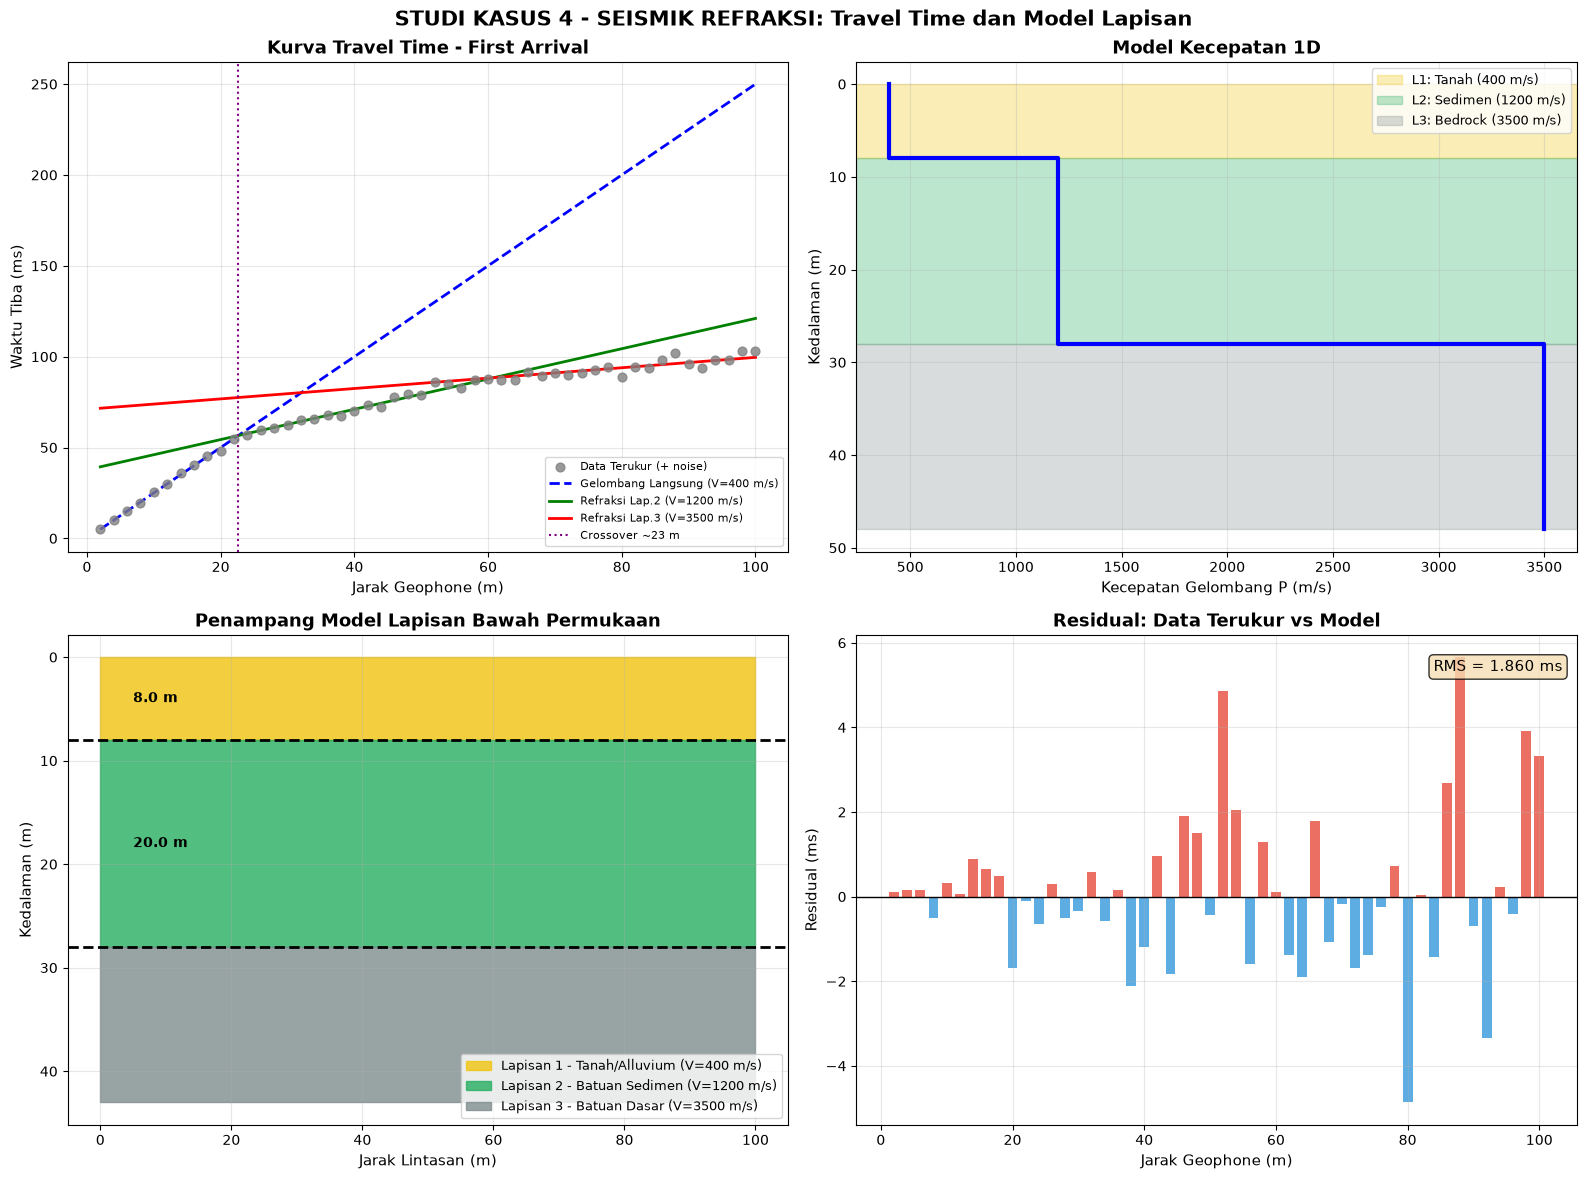

Plot Seismik Refraksi berhasil dibuat!


In [13]:
# ============================================================
#  STUDI KASUS 4: SEISMIK REFRAKSI - VISUALISASI (4 PANEL)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('STUDI KASUS 4 - SEISMIK REFRAKSI: Travel Time dan Model Lapisan',
             fontsize=15, fontweight='bold')

# -- Panel 1: Kurva Travel Time
ax = axes[0, 0]
ax.scatter(offsets, t_observed*1000, s=40, color='gray', alpha=0.8, zorder=4,
           label='Data Terukur (+ noise)')
ax.plot(offsets, t_direct*1000,  'b--', lw=2, label=f'Gelombang Langsung (V={V1:.0f} m/s)')
ax.plot(offsets, t_refr2*1000,   'g-',  lw=2, label=f'Refraksi Lap.2 (V={V2:.0f} m/s)')
ax.plot(offsets, t_refr3*1000,   'r-',  lw=2, label=f'Refraksi Lap.3 (V={V3:.0f} m/s)')
ax.axvline(xc12, color='purple', ls=':', lw=1.5, label=f'Crossover ~{xc12:.0f} m')
ax.set_xlabel('Jarak Geophone (m)')
ax.set_ylabel('Waktu Tiba (ms)')
ax.set_title('Kurva Travel Time - First Arrival', fontweight='bold')
ax.legend(fontsize=8)

# -- Panel 2: Model Kecepatan 1D
ax = axes[0, 1]
depths = [0, H1, H1, H1+H2, H1+H2, H1+H2+20]
vels   = [V1, V1, V2, V2, V3, V3]
ax.step(vels, depths, 'b-', lw=3, where='post')
ax.invert_yaxis()
ax.axhspan(0,        H1,       alpha=0.3, color='#f1c40f',
           label=f'L1: Tanah ({V1:.0f} m/s)')
ax.axhspan(H1,       H1+H2,    alpha=0.3, color='#27ae60',
           label=f'L2: Sedimen ({V2:.0f} m/s)')
ax.axhspan(H1+H2,    H1+H2+20, alpha=0.3, color='#7f8c8d',
           label=f'L3: Bedrock ({V3:.0f} m/s)')
ax.set_xlabel('Kecepatan Gelombang P (m/s)')
ax.set_ylabel('Kedalaman (m)')
ax.set_title('Model Kecepatan 1D', fontweight='bold')
ax.legend(fontsize=9)

# -- Panel 3: Penampang Lapisan 2D
ax = axes[1, 0]
x_sec = np.linspace(0, 100, 200)
ax.fill_between(x_sec, 0,     H1,       color='#f1c40f', alpha=0.8,
                label=f'Lapisan 1 - Tanah/Alluvium (V={V1:.0f} m/s)')
ax.fill_between(x_sec, H1,    H1+H2,    color='#27ae60', alpha=0.8,
                label=f'Lapisan 2 - Batuan Sedimen (V={V2:.0f} m/s)')
ax.fill_between(x_sec, H1+H2, H1+H2+15, color='#7f8c8d', alpha=0.8,
                label=f'Lapisan 3 - Batuan Dasar (V={V3:.0f} m/s)')
ax.axhline(H1,    color='black', lw=2, ls='--')
ax.axhline(H1+H2, color='black', lw=2, ls='--')
ax.invert_yaxis()
ax.set_xlabel('Jarak Lintasan (m)')
ax.set_ylabel('Kedalaman (m)')
ax.set_title('Penampang Model Lapisan Bawah Permukaan', fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.text(5, H1/2,    f'{H1} m', fontsize=10, va='center', fontweight='bold')
ax.text(5, H1+H2/2, f'{H2} m', fontsize=10, va='center', fontweight='bold')

# -- Panel 4: Residual Fitting
ax = axes[1, 1]
residual = (t_observed - t_obs_clean) * 1000
ax.bar(offsets, residual, width=1.5,
       color=np.where(residual > 0, '#e74c3c', '#3498db'), alpha=0.8)
ax.axhline(0, color='black', lw=1)
ax.set_xlabel('Jarak Geophone (m)')
ax.set_ylabel('Residual (ms)')
ax.set_title('Residual: Data Terukur vs Model', fontweight='bold')
ax.text(0.98, 0.95, f'RMS = {rms_resid:.3f} ms', transform=ax.transAxes,
        ha='right', va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig('seismik_refraksi_analisis.png', bbox_inches='tight', dpi=150)
plt.show()
print('Plot Seismik Refraksi berhasil dibuat!')

In [14]:
# ============================================================
#  STUDI KASUS 4: SEISMIK REFRAKSI - ANALISIS
# ============================================================

print('=' * 60)
print('  ANALISIS SEISMIK REFRAKSI')
print('=' * 60)

print('\nPARAMETER MODEL LAPISAN:')
print('-' * 50)
print(f'  Jumlah Lapisan  : 3 lapisan')
print(f'  V1 (Lapisan 1)  : {V1:.0f} m/s  | kedalaman 0-{H1} m')
print(f'  V2 (Lapisan 2)  : {V2:.0f} m/s | kedalaman {H1}-{H1+H2} m')
print(f'  V3 (Lapisan 3)  : {V3:.0f} m/s | kedalaman >{H1+H2} m')
print(f'  Crossover V1/V2 : ~{xc12:.1f} m')
print(f'  RMS Residual    : {rms_resid:.4f} ms')

print('\nNISBAH KECEPATAN ANTAR LAPISAN:')
print(f'  V2/V1 = {V2/V1:.2f}x  (kontras sedang)')
print(f'  V3/V2 = {V3/V2:.2f}x  (kontras tinggi - batas jelas)')
print(f'  V3/V1 = {V3/V1:.2f}x  (kontras sangat tinggi)')

print('\nINTERPRETASI OTOMATIS:')
print('-' * 55)
print(f'''
  Berdasarkan model kecepatan seismik refraksi 3 lapisan:

  LAPISAN 1 (0-{H1} m) | V={V1:.0f} m/s:
    Kecepatan rendah mengindikasikan material lepas atau
    tanah lempung/alluvium di lapisan penutup.

  LAPISAN 2 ({H1}-{H1+H2} m) | V={V2:.0f} m/s:
    Kecepatan sedang-tinggi menunjukkan lapisan lebih kompak,
    kemungkinan batuan sedimen pasiran atau gravel.
    Nisbah V2/V1 = {V2/V1:.1f}x menunjukkan kontras yang signifikan.

  LAPISAN 3 (>{H1+H2} m) | V={V3:.0f} m/s:
    Kecepatan sangat tinggi mengindikasikan batuan dasar
    (bedrock), kemungkinan batuan beku atau metamorf kompak.
    Batas lapisan 2/3 sangat tajam (V3/V2 = {V3/V2:.1f}x).

  KUALITAS MODEL:
    RMS residual = {rms_resid:.4f} ms -> kualitas fitting baik.
    Interpretasi perlu dikonfirmasi dengan data bor atau log.
''')

  ANALISIS SEISMIK REFRAKSI

PARAMETER MODEL LAPISAN:
--------------------------------------------------
  Jumlah Lapisan  : 3 lapisan
  V1 (Lapisan 1)  : 400 m/s  | kedalaman 0-8.0 m
  V2 (Lapisan 2)  : 1200 m/s | kedalaman 8.0-28.0 m
  V3 (Lapisan 3)  : 3500 m/s | kedalaman >28.0 m
  Crossover V1/V2 : ~22.6 m
  RMS Residual    : 1.8598 ms

NISBAH KECEPATAN ANTAR LAPISAN:
  V2/V1 = 3.00x  (kontras sedang)
  V3/V2 = 2.92x  (kontras tinggi - batas jelas)
  V3/V1 = 8.75x  (kontras sangat tinggi)

INTERPRETASI OTOMATIS:
-------------------------------------------------------

  Berdasarkan model kecepatan seismik refraksi 3 lapisan:

  LAPISAN 1 (0-8.0 m) | V=400 m/s:
    Kecepatan rendah mengindikasikan material lepas atau
    tanah lempung/alluvium di lapisan penutup.

  LAPISAN 2 (8.0-28.0 m) | V=1200 m/s:
    Kecepatan sedang-tinggi menunjukkan lapisan lebih kompak,
    kemungkinan batuan sedimen pasiran atau gravel.
    Nisbah V2/V1 = 3.0x menunjukkan kontras yang signifikan.

  LAPI



# **STUDI KASUS 5: GRAVITASI**
## **Interpretasi Peta Bouguer Anomaly**



### Deskripsi Prompt (RTCIKQOV)

| Komponen | Keterangan |
|:---------|:-----------|
| **Role** | AI sebagai pendamping interpretasi hasil analisis gravitasi |
| **Task** | Menginterpretasikan pola anomali gravitasi untuk variasi densitas dan struktur bawah permukaan |
| **Context** | Gravitasi menunjukkan perbedaan densitas melalui perubahan nilai medan gravitasi |
| **Input** | Peta Bouguer anomaly, nilai anomali, lokasi penelitian, peta geologi |
| **Constraints** | Tidak mengolah ulang data; tidak langsung menentukan jenis batuan dari nilai anomali |
| **Output** | Zona anomali positif/negatif, kemungkinan perubahan densitas, kemungkinan struktur geologi |
| **Quality** | Interpretasi berbasis pola anomali dan didukung info geologi |
| **Verification** | Cocokkan interpretasi dengan peta gravitasi dan data geologi/geofisika lain |


In [15]:
# ============================================================
#  STUDI KASUS 5: GRAVITASI
#  Pembuatan Data Sintetis Bouguer Anomaly
# ============================================================

print('=' * 60)
print('  STUDI KASUS 5: GRAVITASI - BOUGUER ANOMALY')
print('=' * 60)

nx_g, ny_g = 100, 80
x_g = np.linspace(0, 100, nx_g)
y_g = np.linspace(0, 80, ny_g)
Xg, Yg = np.meshgrid(x_g, y_g)

# Model Bouguer Anomaly sintetis (mGal)
# Anomali negatif: cekungan sedimen tebal (barat)
ba_basin  = -25.0 * np.exp(-((Xg-25)**2 + (Yg-35)**2) / (2*18**2))
# Anomali positif: intrusi batuan beku / basement dangkal
ba_intrus =  30.0 * np.exp(-((Xg-70)**2 + (Yg-50)**2) / (2*12**2))
# Zona sesar: gradien tajam di x~50 km
ba_fault  =  10.0 * np.tanh((Xg - 50) / 5)

bouguer = ba_basin + ba_intrus + ba_fault - 5.0
bouguer += gaussian_filter(np.random.randn(ny_g, nx_g) * 1.5, sigma=2.5)

bouguer_regional = gaussian_filter(bouguer, sigma=8)
bouguer_residual = bouguer - bouguer_regional

print('\nSTATISTIK BOUGUER ANOMALY:')
df_ba = pd.DataFrame({
    'Komponen':    ['Complete Bouguer', 'Regional', 'Residual'],
    'Min (mGal)':  [f'{bouguer.min():.2f}',          f'{bouguer_regional.min():.2f}',  f'{bouguer_residual.min():.2f}'],
    'Max (mGal)':  [f'{bouguer.max():.2f}',          f'{bouguer_regional.max():.2f}',  f'{bouguer_residual.max():.2f}'],
    'Mean (mGal)': [f'{bouguer.mean():.2f}',         f'{bouguer_regional.mean():.2f}', f'{bouguer_residual.mean():.2f}'],
    'Std (mGal)':  [f'{bouguer.std():.2f}',          f'{bouguer_regional.std():.2f}',  f'{bouguer_residual.std():.2f}']
})
print(df_ba.to_string(index=False))

n_pos = (bouguer > 0).sum()
n_neg = (bouguer < 0).sum()
print(f'\n  Zona anomali positif: {n_pos} piksel ({100*n_pos/bouguer.size:.1f}%)')
print(f'  Zona anomali negatif: {n_neg} piksel ({100*n_neg/bouguer.size:.1f}%)')

  STUDI KASUS 5: GRAVITASI - BOUGUER ANOMALY

STATISTIK BOUGUER ANOMALY:
        Komponen Min (mGal) Max (mGal) Mean (mGal) Std (mGal)
Complete Bouguer     -39.89      34.38       -7.28      18.65
        Regional     -35.64      24.30       -7.28      17.05
        Residual      -6.12      10.22        0.00       2.82

  Zona anomali positif: 3742 piksel (46.8%)
  Zona anomali negatif: 4258 piksel (53.2%)


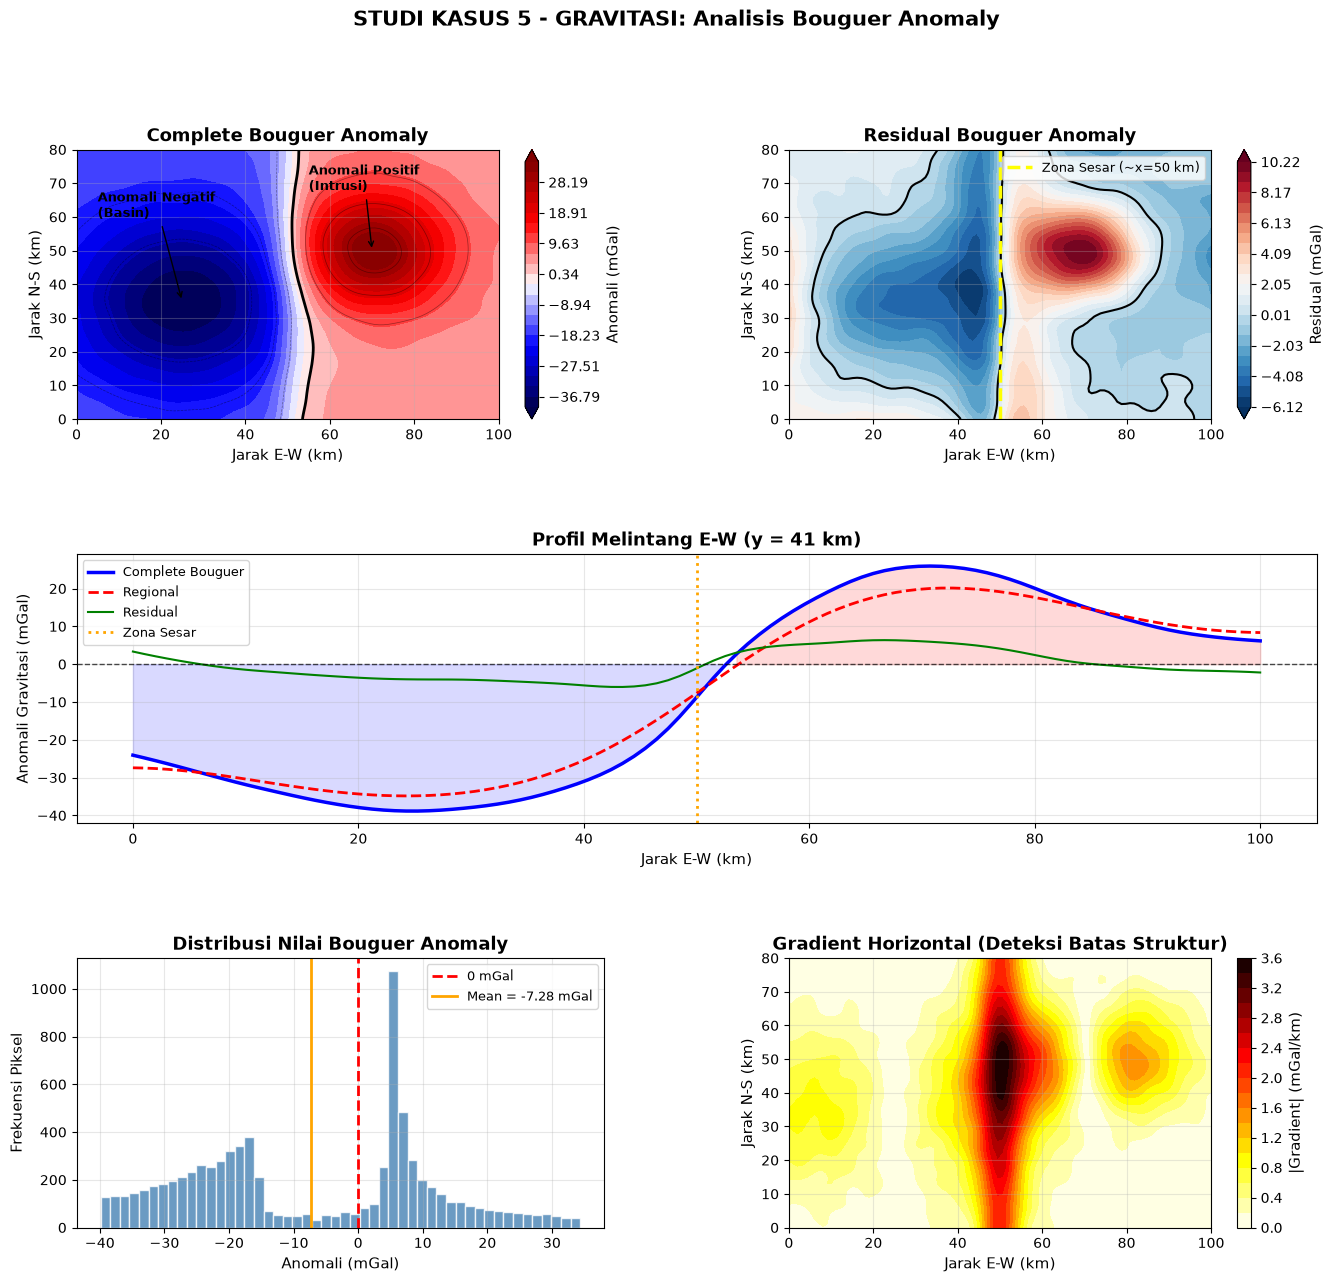

Plot Gravitasi berhasil dibuat!


In [16]:
# ============================================================
#  STUDI KASUS 5: GRAVITASI - VISUALISASI (5 PANEL)
# ============================================================

fig = plt.figure(figsize=(16, 14))
gs  = GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.35)
fig.suptitle('STUDI KASUS 5 - GRAVITASI: Analisis Bouguer Anomaly',
             fontsize=15, fontweight='bold')

# -- Panel 1: Complete Bouguer Anomaly
ax1 = fig.add_subplot(gs[0, 0])
lev_ba = np.linspace(bouguer.min(), bouguer.max(), 25)
im1 = ax1.contourf(Xg, Yg, bouguer, levels=lev_ba, cmap='seismic', extend='both')
plt.colorbar(im1, ax=ax1, label='Anomali (mGal)')
ax1.contour(Xg, Yg, bouguer, levels=[0], colors='k', linewidths=2)
ax1.contour(Xg, Yg, bouguer, levels=8,   colors='k', linewidths=0.5, alpha=0.4)
ax1.set_xlabel('Jarak E-W (km)')
ax1.set_ylabel('Jarak N-S (km)')
ax1.set_title('Complete Bouguer Anomaly', fontweight='bold')
ax1.annotate('Anomali Negatif\n(Basin)', xy=(25, 35), xytext=(5, 60),
             arrowprops=dict(arrowstyle='->', color='black'), fontsize=9, fontweight='bold')
ax1.annotate('Anomali Positif\n(Intrusi)', xy=(70, 50), xytext=(55, 68),
             arrowprops=dict(arrowstyle='->', color='black'), fontsize=9, fontweight='bold')

# -- Panel 2: Residual Bouguer
ax2 = fig.add_subplot(gs[0, 1])
lev_res = np.linspace(bouguer_residual.min(), bouguer_residual.max(), 25)
im2 = ax2.contourf(Xg, Yg, bouguer_residual, levels=lev_res, cmap='RdBu_r', extend='both')
plt.colorbar(im2, ax=ax2, label='Residual (mGal)')
ax2.contour(Xg, Yg, bouguer_residual, levels=[0], colors='k', linewidths=1.5)
ax2.axvline(x=50, color='yellow', lw=2.5, ls='--', label='Zona Sesar (~x=50 km)')
ax2.set_xlabel('Jarak E-W (km)')
ax2.set_ylabel('Jarak N-S (km)')
ax2.set_title('Residual Bouguer Anomaly', fontweight='bold')
ax2.legend(fontsize=9)

# -- Panel 3: Profil Melintang E-W
ax3 = fig.add_subplot(gs[1, :])
row_mid = ny_g // 2
ax3.plot(x_g, bouguer[row_mid, :],          'b-',  lw=2.5, label='Complete Bouguer')
ax3.plot(x_g, bouguer_regional[row_mid, :], 'r--', lw=2,   label='Regional')
ax3.plot(x_g, bouguer_residual[row_mid, :], 'g-',  lw=1.5, label='Residual')
ax3.axhline(0, color='black', lw=1, ls='--', alpha=0.7)
ax3.axvline(50, color='orange', lw=2, ls=':', label='Zona Sesar')
ax3.fill_between(x_g, bouguer[row_mid, :], 0,
                 where=bouguer[row_mid, :] > 0, alpha=0.15, color='red')
ax3.fill_between(x_g, bouguer[row_mid, :], 0,
                 where=bouguer[row_mid, :] < 0, alpha=0.15, color='blue')
ax3.set_xlabel('Jarak E-W (km)')
ax3.set_ylabel('Anomali Gravitasi (mGal)')
ax3.set_title(f'Profil Melintang E-W (y = {y_g[row_mid]:.0f} km)', fontweight='bold')
ax3.legend(fontsize=9)

# -- Panel 4: Histogram
ax4 = fig.add_subplot(gs[2, 0])
ax4.hist(bouguer.flatten(), bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax4.axvline(0, color='red', lw=2, ls='--', label='0 mGal')
ax4.axvline(bouguer.mean(), color='orange', lw=2,
            label=f'Mean = {bouguer.mean():.2f} mGal')
ax4.set_xlabel('Anomali (mGal)')
ax4.set_ylabel('Frekuensi Piksel')
ax4.set_title('Distribusi Nilai Bouguer Anomaly', fontweight='bold')
ax4.legend(fontsize=9)

# -- Panel 5: Gradient Horizontal (deteksi sesar)
ax5 = fig.add_subplot(gs[2, 1])
grad_x = np.gradient(bouguer, axis=1)
im5 = ax5.contourf(Xg, Yg, np.abs(grad_x), levels=20, cmap='hot_r')
plt.colorbar(im5, ax=ax5, label='|Gradient| (mGal/km)')
ax5.set_xlabel('Jarak E-W (km)')
ax5.set_ylabel('Jarak N-S (km)')
ax5.set_title('Gradient Horizontal (Deteksi Batas Struktur)', fontweight='bold')

plt.savefig('gravitasi_bouguer_analisis.png', bbox_inches='tight', dpi=150)
plt.show()
print('Plot Gravitasi berhasil dibuat!')

In [17]:
# ============================================================
#  STUDI KASUS 5: GRAVITASI - ANALISIS & INTERPRETASI
# ============================================================

print('=' * 60)
print('  ANALISIS GRAVITASI - BOUGUER ANOMALY')
print('=' * 60)

idx_min = np.unravel_index(bouguer.argmin(), bouguer.shape)
idx_max = np.unravel_index(bouguer.argmax(), bouguer.shape)
pos_min = (x_g[idx_min[1]], y_g[idx_min[0]])
pos_max = (x_g[idx_max[1]], y_g[idx_max[0]])

print(f'\n  Anomali minimum : {bouguer.min():.2f} mGal di ({pos_min[0]:.1f}, {pos_min[1]:.1f}) km')
print(f'  Anomali maksimum: {bouguer.max():.2f} mGal di ({pos_max[0]:.1f}, {pos_max[1]:.1f}) km')
print(f'  Rentang total   : {bouguer.max()-bouguer.min():.2f} mGal')

zone_pos = bouguer[bouguer > 0]
zone_neg = bouguer[bouguer < 0]
print('\nSTATISTIK ZONA ANOMALI:')
df_zone = pd.DataFrame({
    'Zona':           ['Anomali Positif', 'Anomali Negatif'],
    'Jumlah Piksel':  [len(zone_pos),     len(zone_neg)],
    '% Area':         [f'{100*len(zone_pos)/bouguer.size:.1f}%',
                       f'{100*len(zone_neg)/bouguer.size:.1f}%'],
    'Mean (mGal)':    [f'{zone_pos.mean():.2f}', f'{zone_neg.mean():.2f}'],
    'Ekstrem (mGal)': [f'+{zone_pos.max():.2f}', f'{zone_neg.min():.2f}']
})
print(df_zone.to_string(index=False))

print('\nINTERPRETASI OTOMATIS:')
print('-' * 55)
print(f'''
  Berdasarkan peta Bouguer Anomaly sintetis:

  ANOMALI NEGATIF (Barat, ~x=25 km):
    Nilai terendah {bouguer.min():.1f} mGal di ({pos_min[0]:.0f}, {pos_min[1]:.0f}) km.
    Anomali negatif mengindikasikan material berdensitas
    rendah, kemungkinan cekungan sedimen tebal atau batuan
    vulkanik felsik di bawah permukaan.

  ANOMALI POSITIF (Timur, ~x=70 km):
    Nilai tertinggi {bouguer.max():.1f} mGal di ({pos_max[0]:.0f}, {pos_max[1]:.0f}) km.
    Anomali positif mengindikasikan material berdensitas tinggi,
    kemungkinan adanya intrusi batuan beku mafik atau batuan
    dasar yang muncul lebih dangkal.

  ZONA GRADIEN TINGGI (~x=50 km):
    Perubahan nilai anomali yang tajam mengindikasikan adanya
    batas struktur geologi seperti sesar atau batas formasi
    batuan yang signifikan.

  ANOMALI RESIDUAL:
    Setelah pemisahan komponen regional, anomali residual
    menampilkan detail struktur lokal yang lebih jelas.
    Perlu verifikasi dengan data geologi atau data lapangan.
''')

  ANALISIS GRAVITASI - BOUGUER ANOMALY

  Anomali minimum : -39.89 mGal di (25.3, 34.4) km
  Anomali maksimum: 34.38 mGal di (70.7, 49.6) km
  Rentang total   : 74.27 mGal

STATISTIK ZONA ANOMALI:
           Zona  Jumlah Piksel % Area Mean (mGal) Ekstrem (mGal)
Anomali Positif           3742  46.8%       10.51         +34.38
Anomali Negatif           4258  53.2%      -22.92         -39.89

INTERPRETASI OTOMATIS:
-------------------------------------------------------

  Berdasarkan peta Bouguer Anomaly sintetis:

  ANOMALI NEGATIF (Barat, ~x=25 km):
    Nilai terendah -39.9 mGal di (25, 34) km.
    Anomali negatif mengindikasikan material berdensitas
    rendah, kemungkinan cekungan sedimen tebal atau batuan
    vulkanik felsik di bawah permukaan.

  ANOMALI POSITIF (Timur, ~x=70 km):
    Nilai tertinggi 34.4 mGal di (71, 50) km.
    Anomali positif mengindikasikan material berdensitas tinggi,
    kemungkinan adanya intrusi batuan beku mafik atau batuan
    dasar yang muncul lebih dang